In [8]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [9]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [10]:
# specific

from sklearn.decomposition import PCA, TruncatedSVD
from matplotlib import pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

In [11]:
importlib.reload(read_utils)

<module 'utils_worm.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/notebooks/analysis/../../src/utils_worm/read_utils.py'>

In [12]:
file_ids = range(0, 33 + 1)

In [13]:
filenames = analysis_utils.read_filenames('worm', file_ids)

In [14]:
dimensionaities = np.array([np.load(f'../../out/plots/manifolds/{filename}/gating_space_dim.npy') for filename in filenames])

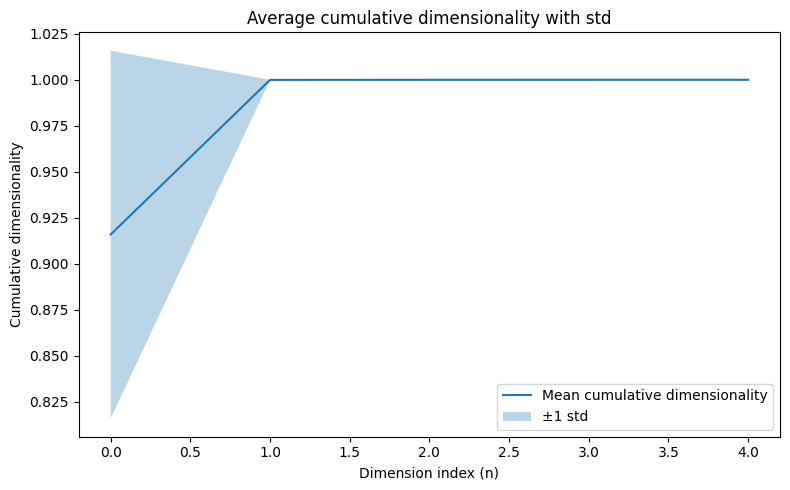

In [21]:
# Compute cumulative sums for each sample
cumulative_dims = np.cumsum(dimensionaities, axis=1)

# Compute mean and std across samples for each dimension index
dim_mean = np.mean(cumulative_dims, axis=0)
dim_std = np.std(cumulative_dims, axis=0)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(dim_mean, label='Mean cumulative dimensionality')
plt.fill_between(np.arange(len(dim_mean)), dim_mean - dim_std, dim_mean + dim_std, alpha=0.3, label='±1 std')
plt.xlabel('Dimension index (n)')
plt.ylabel('Cumulative dimensionality')
plt.title('Average cumulative dimensionality with std')
plt.legend()
plt.tight_layout()
plt.show()
